# El sistema con 5 semillas: resumen

Este notebook es el paso 4 de la carpeta `semillas`: compara los 5 sistemas completos, el de producción (semilla 42) y los de las semillas 1, 2, 3 y 4. No entrena nada: lee las predicciones que dejaron los pasos 1 a 3 y, para la semilla 42, las de los notebooks de cada modelo.

La pregunta es si el resultado del sistema **fue suerte de la semilla 42**. Antes de ver los resultados se fijó cómo leerlos:
- se reporta la desviación estándar entre semillas del MF1 de test con canales al azar, solo con Fpz-Cz y con los 4 canales;
- si es de 0.005 o menos, el resultado es **estable**;
- la semilla 42 debe caer dentro del rango de las otras;
- no se elige "la mejor semilla": eso sería elegir con el test. Producción sigue con la 42.

El desarrollo se organiza de la siguiente manera:

1. **Librerías**
2. **Rutas y parámetros**
3. **Predicciones**
4. **Por combinación**
5. **Canales al azar**
6. **Confianza**
7. **Resumen**
8. **Conclusiones**

## 1. Librerías

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 2. Rutas y parámetros

El bootstrap usa siempre la semilla 42 y 2000 remuestras: así las 5 semillas se miden con los mismos sujetos remuestreados y las mismas combinaciones sorteadas, y las diferencias entre ellas son solo del entrenamiento.

In [2]:
# Raíz del repositorio: la carpeta que tiene particiones.json
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "particiones.json").exists())
PROCESADOS = RAIZ / "data" / "procesados"
MODELOS = RAIZ / "experimentacion" / "semillas" / "modelos"

SEMILLAS = [42, 1, 2, 3, 4]
SEED = 42          # la del bootstrap: la misma para todas las semillas
N_BOOT = 2000
ESTADIOS = ["W", "N1", "N2", "N3", "REM"]
K = len(ESTADIOS)
DE_ESTABLE = 0.005   # regla fijada antes de ver los resultados

particion = json.loads((RAIZ / "particiones.json").read_text())
CONFIGS = list(particion["combinaciones"])
FOLDS = [f"fold_{f['fold']}" for f in particion["folds"]]


def carpeta(semilla, pieza):
    """Dónde dejó sus predicciones cada pieza: la 42 en data/procesados/<pieza>, las demás en semillas/."""
    return PROCESADOS / pieza if semilla == 42 else PROCESADOS / "semillas" / f"semilla_{semilla}" / pieza


def sistema_json(semilla):
    return json.loads(((RAIZ / "modelo") if semilla == 42 else MODELOS / f"semilla_{semilla}").joinpath("sistema.json").read_text())

## 3. Predicciones

Para cada semilla: A, B y el sistema (el meta-modelo), en la CV (fuera de fold, 62 sujetos) y en el test (16 sujetos).

In [3]:
# Funciones para leer las predicciones de A, B y el meta-modelo de una semilla
def load_a(semilla):
    """'oof'/'test' -> combinación -> noche -> (y, p)"""
    out = {"oof": {c: {} for c in CONFIGS}, "test": {c: {} for c in CONFIGS}}
    for name in FOLDS + ["final"]:
        z = np.load(carpeta(semilla, "modelo_a_xgboost_100_features") / "folds" / f"{name}.npz")
        for k in z.files:
            cfg, n, kind = k.split("__")
            if kind == "y":
                out["test" if name == "final" else "oof"][cfg][n] = (z[k], z[f"{cfg}__{n}__pred"])
    return out


def load_b(semilla):
    out = {"oof": {c: {} for c in CONFIGS}, "test": {c: {} for c in CONFIGS}}
    for name in FOLDS + ["final"]:
        z = np.load(carpeta(semilla, "modelo_b_red") / "predicciones" / f"{name}.npz")
        for k in z.files:
            cfg, n = k.split("__")
            if cfg in CONFIGS:
                out["test" if name == "final" else "oof"][cfg][n] = (z[f"y__{n}"], z[k])
    return out


def load_meta(semilla):
    z = np.load(carpeta(semilla, "meta_modelo") / "predicciones.npz")
    out = {"oof": {c: {} for c in CONFIGS}, "test": {c: {} for c in CONFIGS}}
    for k in z.files:
        key, c, n, kind = k.split("__")
        if kind == "y":
            out[key][c][n] = (z[k], z[f"{key}__{c}__{n}__pred"])
    return out


P = {s: {"A": load_a(s), "B": load_b(s), "sistema": load_meta(s)} for s in SEMILLAS}
print({s: f"{len(P[s]['sistema']['oof']['fpz'])} noches de CV y {len(P[s]['sistema']['test']['fpz'])} de test" for s in SEMILLAS})

{42: '121 noches de CV y 32 de test', 1: '121 noches de CV y 32 de test', 2: '121 noches de CV y 32 de test', 3: '121 noches de CV y 32 de test', 4: '121 noches de CV y 32 de test'}


In [4]:
# Funciones para la matriz de confusión y las métricas
def confusion(y, p):
    v = y >= 0
    return np.bincount(y[v] * K + p.argmax(1)[v], minlength=K * K).reshape(K, K)


def metrics_quick(cm):
    n, tp = cm.sum(), np.diag(cm)
    rows, cols = cm.sum(1), cm.sum(0)
    f1 = np.divide(2 * tp, rows + cols, out=np.zeros(K), where=(rows + cols) > 0)
    pe = (rows * cols).sum() / n**2
    return {"acc": tp.sum() / n, "mf1": f1.mean(), "kappa": (tp.sum() / n - pe) / (1 - pe), "f1_N1": f1[1]}


def metrics_of(preds):
    """noche -> (y, p)  ->  métricas de todas las noches juntas"""
    return metrics_quick(sum(confusion(y, p) for y, p in preds.values()))


def con_media(tabla):
    """Agrega la media, la desviación estándar y el rango entre semillas."""
    return tabla.assign(media=tabla.mean(1), de=tabla.std(1), mín=tabla.min(1), máx=tabla.max(1))

## 4. Por combinación

MF1 de A, B y el sistema en las 12 combinaciones, como media ± desviación estándar de las 5 semillas. Solo se evalúan las épocas con etiqueta.

In [5]:
# MF1 de A, B y el sistema por combinación: media ± de de las 5 semillas
filas = []
for c in CONFIGS:
    fila = {"combinación": c}
    for pieza in ("A", "B", "sistema"):
        for key, nombre in (("oof", "CV"), ("test", "test")):
            v = np.array([metrics_of(P[s][pieza][key][c])["mf1"] for s in SEMILLAS])
            fila[f"{pieza} {nombre}"] = f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
    filas.append(fila)
pd.DataFrame(filas).set_index("combinación")

,A CV,A test,B CV,B test,sistema CV,sistema test
combinación,,,,,,
fpz,0.760 ± 0.000,0.721 ± 0.002,0.762 ± 0.007,0.751 ± 0.002,0.801 ± 0.002,0.772 ± 0.003
pz,0.717 ± 0.001,0.691 ± 0.001,0.735 ± 0.003,0.714 ± 0.003,0.761 ± 0.001,0.736 ± 0.002
eeg2,0.777 ± 0.001,0.735 ± 0.001,0.778 ± 0.006,0.765 ± 0.002,0.810 ± 0.001,0.781 ± 0.004
fpz_eog,0.771 ± 0.001,0.736 ± 0.001,0.777 ± 0.006,0.762 ± 0.003,0.810 ± 0.001,0.781 ± 0.002
pz_eog,0.742 ± 0.000,0.708 ± 0.002,0.769 ± 0.005,0.739 ± 0.002,0.788 ± 0.001,0.754 ± 0.003
eeg2_eog,0.784 ± 0.001,0.746 ± 0.001,0.787 ± 0.006,0.767 ± 0.002,0.817 ± 0.000,0.786 ± 0.003
fpz_emg,0.769 ± 0.001,0.731 ± 0.001,0.768 ± 0.006,0.752 ± 0.002,0.802 ± 0.001,0.770 ± 0.003
pz_emg,0.728 ± 0.001,0.706 ± 0.001,0.740 ± 0.002,0.717 ± 0.003,0.765 ± 0.001,0.738 ± 0.001
eeg2_emg,0.782 ± 0.001,0.746 ± 0.001,0.780 ± 0.006,0.762 ± 0.003,0.811 ± 0.001,0.780 ± 0.004


El MF1 de test del sistema, semilla por semilla:

In [6]:
# MF1 de test del sistema por combinación y semilla
test_sistema = pd.DataFrame({f"semilla {s}": {c: metrics_of(P[s]["sistema"]["test"][c])["mf1"] for c in CONFIGS}
                             for s in SEMILLAS})
con_media(test_sistema).style.format(precision=3)

,semilla 42,semilla 1,semilla 2,semilla 3,semilla 4,media,de,mín,máx
fpz,0.772,0.775,0.767,0.773,0.773,0.772,0.003,0.767,0.775
pz,0.735,0.737,0.734,0.736,0.738,0.736,0.002,0.734,0.738
eeg2,0.780,0.784,0.776,0.780,0.786,0.781,0.004,0.776,0.786
fpz_eog,0.779,0.784,0.779,0.781,0.782,0.781,0.002,0.779,0.784
pz_eog,0.751,0.758,0.753,0.754,0.755,0.754,0.003,0.751,0.758
eeg2_eog,0.784,0.788,0.782,0.786,0.789,0.786,0.003,0.782,0.789
fpz_emg,0.771,0.772,0.765,0.771,0.773,0.770,0.003,0.765,0.773
pz_emg,0.737,0.738,0.737,0.739,0.739,0.738,0.001,0.737,0.739
eeg2_emg,0.780,0.782,0.773,0.781,0.784,0.780,0.004,0.773,0.784
fpz_eog_emg,0.778,0.780,0.777,0.781,0.780,0.779,0.001,0.777,0.781


## 5. Canales al azar

La cifra global del sistema, como en `meta_modelo/2_confianza.ipynb`: en cada remuestra se eligen 16 sujetos con reemplazo y a cada noche se le sortea una de las 12 combinaciones.

In [7]:
# Bootstrap con una combinación al azar por noche: las mismas remuestras para las 5 semillas
NOCHES_TEST = sorted(P[42]["sistema"]["test"]["fpz"])
SUJETOS_TEST = sorted({int(n[3:5]) for n in NOCHES_TEST})
por_sujeto = {s: [i for i, n in enumerate(NOCHES_TEST) if int(n[3:5]) == s] for s in SUJETOS_TEST}


def al_azar(meta_test):
    """Métricas de las 12 combinaciones juntas y de 2000 remuestras con una combinación al azar por noche."""
    cm = np.stack([np.stack([confusion(*meta_test[c][n]) for c in CONFIGS]) for n in NOCHES_TEST])
    rng = np.random.default_rng(SEED)
    boot = []
    for _ in range(N_BOOT):
        idx = np.concatenate([por_sujeto[s] for s in rng.choice(SUJETOS_TEST, size=len(SUJETOS_TEST), replace=True)])
        pick = rng.integers(0, len(CONFIGS), size=len(idx))
        boot.append(metrics_quick(cm[idx, pick].sum(0)))
    return metrics_quick(cm.sum((0, 1))), pd.DataFrame(boot)


AZAR = {s: al_azar(P[s]["sistema"]["test"]) for s in SEMILLAS}
pd.DataFrame([{"semilla": s, "MF1": pt["mf1"], "IC 95 %": f"[{b.mf1.quantile(0.025):.3f}, {b.mf1.quantile(0.975):.3f}]",
               "κ": pt["kappa"], "F1 N1": pt["f1_N1"]} for s, (pt, b) in AZAR.items()]).set_index("semilla").style.format(precision=3)

,MF1,IC 95 %,κ,F1 N1
semilla,,,,
42,0.767,"[0.728, 0.797]",0.738,0.514
1,0.770,"[0.731, 0.800]",0.742,0.522
2,0.764,"[0.724, 0.795]",0.734,0.510
3,0.769,"[0.731, 0.797]",0.742,0.513
4,0.770,"[0.730, 0.800]",0.738,0.526


## 6. Confianza

Con el umbral que eligió la CV de cada semilla: qué parte de la noche entrega el sistema solo, cuánto acierta ahí y, en lo que queda para revisar, cuántas veces la correcta está entre las 2 primeras opciones.

In [8]:
# Confianza en el test con el umbral de cada semilla (12 combinaciones juntas)
def night_stats(y, p, umbral):
    v = y >= 0
    y, p = y[v], p[v]
    o = np.argsort(-p, 1)
    seg, ok, top2 = p.max(1) >= umbral, o[:, 0] == y, (o[:, 0] == y) | (o[:, 1] == y)
    return {"n": len(y), "seg": seg.sum(), "ok_seg": (ok & seg).sum(), "dud": (~seg).sum(), "top2_dud": (top2 & ~seg).sum()}


CONF = {}
for s in SEMILLAS:
    umbral = sistema_json(s)["umbral_confianza"]
    st = [night_stats(*P[s]["sistema"]["test"][c][n], umbral) for c in CONFIGS for n in NOCHES_TEST]
    t = {k: sum(x[k] for x in st) for k in st[0]}
    CONF[s] = {"umbral": umbral, "entrega": t["seg"] / t["n"], "acierto ahí": t["ok_seg"] / t["seg"],
               "2 opciones en revisar": t["top2_dud"] / t["dud"]}
pd.DataFrame(CONF).T.style.format(precision=3)

,umbral,entrega,acierto ahí,2 opciones en revisar
42,0.650,0.802,0.878,0.861
1,0.650,0.816,0.875,0.866
2,0.650,0.792,0.878,0.865
3,0.650,0.809,0.878,0.867
4,0.650,0.810,0.874,0.876


## 7. Resumen

Todas las cifras juntas. Las columnas son las semillas; luego, la media, la desviación estándar y el rango.

In [9]:
# Tabla resumen: cada métrica con las 5 semillas, su media ± de y su rango
def fila(nombre, valores):
    v = np.array([valores[s] for s in SEMILLAS])
    return {"métrica": nombre, **{str(s): valores[s] for s in SEMILLAS}, "media": v.mean(), "de": v.std(ddof=1),
            "mín": v.min(), "máx": v.max()}


mf1_test = lambda c: {s: metrics_of(P[s]["sistema"]["test"][c])["mf1"] for s in SEMILLAS}  # noqa: E731
RESUMEN = pd.DataFrame([
    fila("MF1, canales al azar", {s: AZAR[s][0]["mf1"] for s in SEMILLAS}),
    fila("κ, canales al azar", {s: AZAR[s][0]["kappa"] for s in SEMILLAS}),
    fila("F1 N1, canales al azar", {s: AZAR[s][0]["f1_N1"] for s in SEMILLAS}),
    fila("MF1, solo Fpz-Cz", mf1_test("fpz")),
    fila("MF1, 4 canales", mf1_test("eeg2_eog_emg")),
    fila("MF1, solo Pz-Oz", mf1_test("pz")),
    fila("umbral de confianza", {s: CONF[s]["umbral"] for s in SEMILLAS}),
    fila("fracción que entrega el sistema", {s: CONF[s]["entrega"] for s in SEMILLAS}),
    fila("acierto de lo que entrega", {s: CONF[s]["acierto ahí"] for s in SEMILLAS}),
    fila("revisar: correcta entre 2", {s: CONF[s]["2 opciones en revisar"] for s in SEMILLAS}),
]).set_index("métrica")
RESUMEN.style.format(precision=3)

,42,1,2,3,4,media,de,mín,máx
métrica,,,,,,,,,
"MF1, canales al azar",0.767,0.770,0.764,0.769,0.770,0.768,0.002,0.764,0.770
"κ, canales al azar",0.738,0.742,0.734,0.742,0.738,0.739,0.003,0.734,0.742
"F1 N1, canales al azar",0.514,0.522,0.510,0.513,0.526,0.517,0.007,0.510,0.526
"MF1, solo Fpz-Cz",0.772,0.775,0.767,0.773,0.773,0.772,0.003,0.767,0.775
"MF1, 4 canales",0.783,0.786,0.781,0.785,0.787,0.784,0.002,0.781,0.787
"MF1, solo Pz-Oz",0.735,0.737,0.734,0.736,0.738,0.736,0.002,0.734,0.738
umbral de confianza,0.650,0.650,0.650,0.650,0.650,0.650,0.000,0.650,0.650
fracción que entrega el sistema,0.802,0.816,0.792,0.809,0.810,0.806,0.009,0.792,0.816
acierto de lo que entrega,0.878,0.875,0.878,0.878,0.874,0.877,0.002,0.874,0.878


Las mismas cifras en una gráfica, con el IC 95 % de cada semilla. En rojo, la 42. La línea punteada es la meta de MF1 0.75.

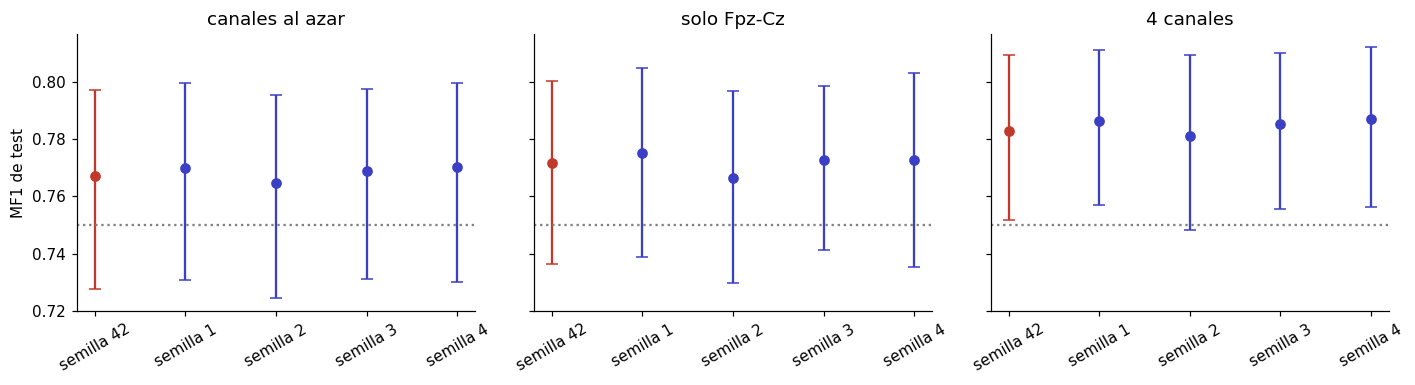

In [10]:
# MF1 de test de cada semilla, con su IC 95 % por bootstrap
def ic_combinacion(semilla, c):
    cms = {}
    for n, (y, p) in P[semilla]["sistema"]["test"][c].items():
        cms[int(n[3:5])] = cms.get(int(n[3:5]), 0) + confusion(y, p)
    st = np.stack([cms[s] for s in sorted(cms)])
    rng = np.random.default_rng(SEED)
    b = np.array([metrics_quick(st[rng.integers(0, len(st), len(st))].sum(0))["mf1"] for _ in range(N_BOOT)])
    return np.quantile(b, [0.025, 0.975])


paneles = [("canales al azar", {s: (AZAR[s][0]["mf1"], AZAR[s][1].mf1.quantile([0.025, 0.975]).values) for s in SEMILLAS})]
for c, nombre in [("fpz", "solo Fpz-Cz"), ("eeg2_eog_emg", "4 canales")]:
    paneles.append((nombre, {s: (metrics_of(P[s]["sistema"]["test"][c])["mf1"], ic_combinacion(s, c)) for s in SEMILLAS}))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (nombre, d) in zip(axes, paneles):
    for i, s in enumerate(SEMILLAS):
        mf1, (lo, hi) = d[s]
        ax.errorbar(i, mf1, yerr=[[mf1 - lo], [hi - mf1]], fmt="o", capsize=4,
                    color="#c0392b" if s == 42 else "#3b3fc4")
    ax.axhline(0.75, ls=":", color="gray")
    ax.set_xticks(range(len(SEMILLAS)), [f"semilla {s}" for s in SEMILLAS], rotation=30)
    ax.set_title(nombre)
axes[0].set_ylabel("MF1 de test")
plt.tight_layout()
plt.show()

La regla fijada al principio:

In [11]:
# ¿Es estable? La regla fijada antes de ver los resultados
for metrica in ["MF1, canales al azar", "MF1, solo Fpz-Cz", "MF1, 4 canales"]:
    r = RESUMEN.loc[metrica]
    dentro = r["mín"] <= r["42"] <= r["máx"]
    lugar = int((RESUMEN.loc[metrica, [str(s) for s in SEMILLAS]] > r["42"]).sum()) + 1
    print(f"{metrica}: de {r['de']:.3f} ({'estable' if r['de'] <= DE_ESTABLE else 'NO estable'}) · "
          f"la 42 da {r['42']:.3f}, puesto {lugar} de {len(SEMILLAS)}")
b42 = AZAR[42][1].mf1
print(f"\nancho del IC 95 % de la semilla 42 con canales al azar: {b42.quantile(0.975) - b42.quantile(0.025):.3f} "
      f"· rango entre semillas: {RESUMEN.loc['MF1, canales al azar', 'máx'] - RESUMEN.loc['MF1, canales al azar', 'mín']:.3f}")

MF1, canales al azar: de 0.002 (estable) · la 42 da 0.767, puesto 4 de 5
MF1, solo Fpz-Cz: de 0.003 (estable) · la 42 da 0.772, puesto 4 de 5
MF1, 4 canales: de 0.002 (estable) · la 42 da 0.783, puesto 4 de 5

ancho del IC 95 % de la semilla 42 con canales al azar: 0.070 · rango entre semillas: 0.006


## 8. Conclusiones

- **El resultado no fue suerte de la semilla 42.** Con una combinación de canales al azar por noche, las 5 semillas dan MF1 0.768 ± 0.002 (de 0.764 a 0.770) y κ 0.739 ± 0.003. Solo con Fpz-Cz, 0.772 ± 0.003; con los 4 canales, 0.784 ± 0.002; solo con Pz-Oz, 0.736 ± 0.002.
- La desviación estándar queda bajo el límite de 0.005 fijado al principio en las tres cifras: el sistema es **estable**.
- La semilla 42, la de producción, queda 4.ª de 5 en las tres, a 0.001 de la media: el sistema en producción está un poco por debajo del promedio, no por encima.
- La diferencia entre semillas (0.006 de rango con canales al azar) es mucho menor que la incertidumbre por tener solo 16 sujetos de test (el IC 95 % mide 0.070): la cifra está limitada por el tamaño del test, no por la semilla.
- El F1 de N1, el estadio más difícil, varía ± 0.007 y siempre queda entre 0.510 y 0.526.
- El umbral de confianza sale 0.65 en las 5 semillas, y el sistema entrega entre el 79 % y el 82 % de la noche con un acierto de 0.874 a 0.878.
- Una mejora futura del sistema tendría que superar claramente esta variación (unos 0.003) para no confundirse con el efecto de la semilla.